# Does the regularised MGD model reproduce the data? A test with known truth (1-D bimodal density)

- **Question.** Does the regularised model built from MGD's coefficients reproduce the data moments? Can we sample
  it with MALA, and correct it when it does not?
- **Method.** 1-D two-well density known exactly; 3 independent datasets of 10⁶ samples; two barrier heights;
  exact integrals as the referee.
- **Result.**
  - MGD's walkers reproduce the data moments; the regularised model does not (odd moments off by up to tens of
    standard errors).
  - Choosing λ by moment matching helps (up to 4×) but does not close the gap.
  - A Newton refit with moments from MALA samples does: from the regularised coefficients it reaches the
    Cramér–Rao bound in one step, about 10⁴ times closer to the truth than MGD's raw coefficients.

## 0. Setup

- **True density** p\*(x) ∝ exp(−βx⁴ + 5βx² + βx/2): two wells at x ≈ ±1.6, the right one deeper.
  - β = 0.1: low barrier (≈ 0.5 nats); β = 0.9: high barrier (≈ 5 nats).
  - Barrier at x_b ≈ −0.05; P(x < x_b) = weight of the left well.
- **Data:** 3 runs per β, each with its own n = 10⁶ samples (seeds 42–44). m = data moments E[x], …, E[x⁴].
- **Model:** p_θ(x) ∝ exp(θ·φ(x)), φ = (x, x²/2, x³/3, x⁴/4); a density only if θ₄ < 0.
  - Truth: θ\* = β(1/2, 10, 0, −4).
  - Maximum-entropy model of the data = the p_θ whose moments equal m.
- **MGD:** moves 10⁶ walkers from a Gaussian to the data in 5·10⁴ steps, forcing their moments to follow the data;
  at each step it estimates θ_t. **θ₁** = estimate at the last step (noisy).
- **Regularised model p_reg:** Θ_reg(λ) = smooth curve fitted to θ_t over the whole run, λ = amount of smoothing;
  p_reg uses its value at t = 1. **λ_A** = the λ used so far (rule A).
- **MALA:** Metropolis-adjusted Langevin algorithm, draws samples of a given density; the only way to get moments of
  p_reg in high dimension (turbulence). In 1-D the exact integrals serve as referee.
- **Measures:**
  - SE = standard error of an average; z = error / SE.
  - D = moment mismatch: the four moment errors combined, in units of the data noise; r/n = 4·10⁻⁶ = pure noise
    level (r = 4 statistics).
  - KL(p\* ‖ p) = distance of a model from the truth, in nats.
  - **Cramér–Rao bound r/2n = 2·10⁻⁶ nats:** the smallest KL any estimate from n samples can reach on average.
- **Runs:** figures show the average over the 3 runs (geometric mean ×/÷ geometric std on log axes, mean ± std on
  linear axes).

In [1]:
%matplotlib inline
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

from bimodal_exact import GRID, X_B, kl_exact, log_density, moments, newton, theta_star

RES = Path('results_bim_theta_beta')
SEPT = RES / 'bim_theta_beta_sweep_20260924_152418'
NEW = {0.1: RES / 'mala_start_beta0.1_1123/beta_0.1000', 0.9: RES / 'mala_start_beta0.9_1123/beta_0.9000'}
BETAS, RUNS, R, N_DATA = (0.1, 0.9), (0, 1, 2), 4, 10**6
CR = R / (2 * N_DATA)                                          # Cramér–Rao bound in KL
A = torch.arange(1, 5)
MOMENTS = ['E[x]', 'E[x²]', 'E[x³]', 'E[x⁴]']
sel = {b: torch.load(SEPT / f'beta_{b:.4f}/lam_selection_A.pt', weights_only=False) for b in BETAS}
data = {b: torch.load(NEW[b] / 'data_moments.pt', weights_only=False)['runs'] for b in BETAS}
mgd = {(b, k): torch.load(NEW[b] / f'mgd/run_{k:03d}.pt', weights_only=False) for b in BETAS for k in RUNS}
summary = {(s['beta'], s['run'], s['start'], s['lam_rule']): s
           for s in torch.load(RES / 'mala_summary.pt', weights_only=False)}
c2 = torch.load(RES / 'newton_mala_summary.pt', weights_only=False)
LAMS = sel[0.1]['lams']
C_INV = {b: torch.linalg.inv(moments(theta_star(b))[1]) for b in BETAS}
CAT, MARK = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100'], ['o', 's', '^', 'D']     # fixed series colours / markers
N_MALA = 1_000_000                                             # MALA chains per Newton step

def theta_reg(b, k, lam):
    return sel[b]['theta_final_reg'][k, LAMS.index(lam)].double()

def mismatch(E, b, k):
    d = torch.as_tensor(E, dtype=torch.float64) - data[b][k]['m']
    return float(d @ C_INV[b] @ d)

def newton_mala(b):
    """MALA-Newton records (N = N_MALA) for the 3 runs of beta b, in run order."""
    return sorted((r for r in c2 if r['beta'] == b and r['n_walkers'] == N_MALA), key=lambda r: r['run'])

def gmean(v, axis=0):
    """Geometric mean and geometric standard deviation (a factor) over runs."""
    lv = np.log(np.asarray(v, dtype=float))
    return np.exp(lv.mean(axis)), np.exp(lv.std(axis, ddof=1))

def gpoints(ax, series, ylabel, refs=(), title='', colors=None):
    """One point per series (categories on the x axis): geometric mean over the runs, bars ×/÷ geometric std."""
    for i, vals in enumerate(series.values()):
        g, s = gmean(vals)
        ax.errorbar(i, g, yerr=[[g - g / s], [g * s - g]], fmt=MARK[i % 4], color=(colors or CAT)[i % 4],
                    ms=9, capsize=5)
    for j, (y, lab) in enumerate(refs):
        ax.axhline(y, color='0.4', ls=('--', ':')[j], lw=1.2, label=lab)
    ax.set(xticks=range(len(series)), xlim=(-0.6, len(series) - 0.4), yscale='log', ylabel=ylabel, title=title)
    ax.set_xticklabels(list(series), fontsize=9)
    if refs:
        ax.legend(fontsize=8)

def gband(ax, x, curves, color, label):
    """Geometric mean over runs of several curves (runs, len(x)) with a ×/÷ geometric-std band."""
    g, s = gmean(curves)
    ax.plot(x, g, color=color, lw=1.6, label=label)
    ax.fill_between(x, g / s, g * s, color=color, alpha=0.2, lw=0)

## 1. MGD reproduces the data moments

- |z| = |walker average − data average| / data SE, per moment; mean ± std over the 3 runs.
- Dashed line: one standard error.

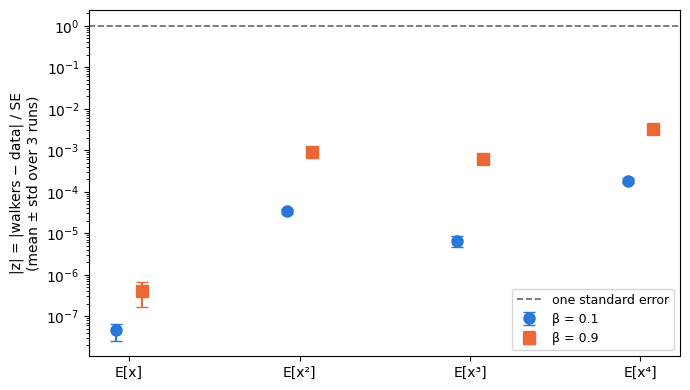

In [2]:
fig, ax = plt.subplots(figsize=(7, 4))
for i, b in enumerate(BETAS):
    z = np.array([((mgd[b, k]['x_final'].double()[:, None] ** A).mean(0) - data[b][k]['m']).abs().numpy()
                  / data[b][k]['se'].numpy() for k in RUNS])                 # (runs, 4)
    ax.errorbar(A.numpy() + (i - 0.5) * 0.15, z.mean(0), yerr=z.std(0, ddof=1), fmt=MARK[i], color=CAT[i], ms=8,
                capsize=4, label=f'β = {b}')
ax.axhline(1, color='0.4', ls='--', lw=1.2, label='one standard error')
ax.set(xticks=A.numpy(), xticklabels=MOMENTS, yscale='log',
       ylabel='|z| = |walkers − data| / SE\n(mean ± std over 3 runs)')
ax.legend(fontsize=9)
fig.tight_layout()

**Conclusion.**
- The walkers match the data moments far below the sampling error, as MGD imposes them.
- So "matches the MGD walkers" = "matches the data moments m" in what follows.

## 2. The coefficients: truth, MGD and regularised

- One panel per coefficient: true value (line), MGD's θ₁ and Θ_reg(λ_A), mean ± std over the 3 runs.
- KL of the two models to the truth over 100 runs: `kl_bimodal.ipynb`.
- Second figure: true and regularised densities (run 0, log scale) with the MGD walker histogram.

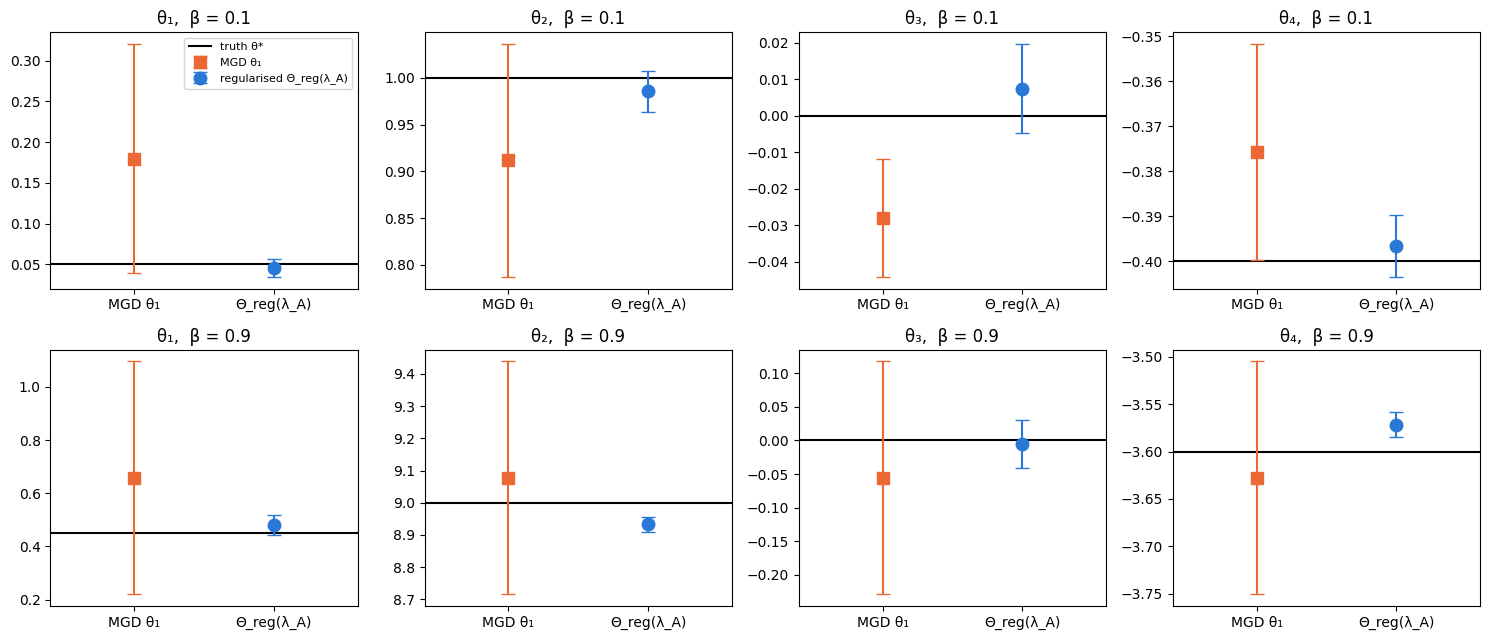

In [3]:
MODELS = {'MGD θ₁': (CAT[1], lambda b, k: mgd[b, k]['theta_final_mgd'].double()),
          'regularised Θ_reg(λ_A)': (CAT[0], lambda b, k: theta_reg(b, k, sel[b]['lam_selected']))}
fig, axes = plt.subplots(2, 4, figsize=(15, 6.5))
for row, b in enumerate(BETAS):
    for a, ax in enumerate(axes[row]):
        ax.axhline(float(theta_star(b)[a]), color='k', lw=1.5, label='truth θ*')
        for i, (name, (c, f)) in enumerate(MODELS.items()):
            v = np.array([float(f(b, k)[a]) for k in RUNS])
            ax.errorbar(i, v.mean(), yerr=v.std(ddof=1), fmt=('s', 'o')[i], color=c, ms=9, capsize=5, label=name)
        ax.set(xticks=[0, 1], xticklabels=['MGD θ₁', 'Θ_reg(λ_A)'], xlim=(-0.6, 1.6), title=f'θ{"₁₂₃₄"[a]},  β = {b}')
axes[0, 0].legend(fontsize=8)
fig.tight_layout()

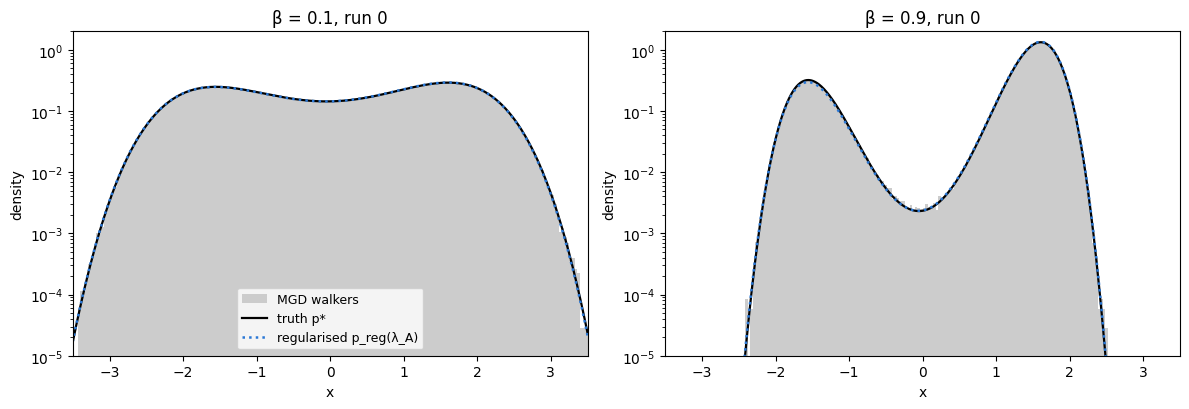

In [4]:
x, k = GRID.numpy(), 0
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for ax, b in zip(axes, BETAS):
    ax.hist(mgd[b, k]['x_final'].numpy(), bins=200, range=(-3.5, 3.5), density=True, color='0.8', label='MGD walkers')
    ax.plot(x, log_density(theta_star(b))[0].exp().numpy(), 'k', lw=1.6, label='truth p*')
    ax.plot(x, log_density(theta_reg(b, k, sel[b]['lam_selected']))[0].exp().numpy(), color=CAT[0], ls=':', lw=1.8,
            label='regularised p_reg(λ_A)')
    ax.set(yscale='log', ylim=(1e-5, 2), xlim=(-3.5, 3.5), xlabel='x', ylabel='density', title=f'β = {b}, run {k}')
axes[0].legend(fontsize=9)
fig.tight_layout()

**Conclusion.**
- MGD's raw coefficients scatter widely from run to run; the regularised ones much less, and close to the truth.
- Close, not on it: at β = 0.9, θ₂ and θ₄ of Θ_reg miss the truth by more than their spread (systematic bias).
- On the density plot p_reg is indistinguishable from p\*; section 4 shows its error is still above the data noise.

## 3. Sampling the regularised model with MALA

- 10⁵ independent chains per run, 10 000 steps (two runs of 5000, the second continuing the first); step size h = 1 (β = 0.1) and 0.1 (β = 0.9), acceptance 0.62 and 0.58.
- Start: 10⁵ of the final MGD walkers (the intended use).
- Control: start from a standard Gaussian. Two starts ending at the same values = the convergence check usable when
  the exact answer is unknown (turbulence).
- Top: left-well weight, |MALA − exact| / SE; below the dashed line (2 SE) = as good as exact samples.
- Bottom: the 4 moments, mean of z² with each moment's own SE (no covariance needed); ≈ 1 for exact samples.

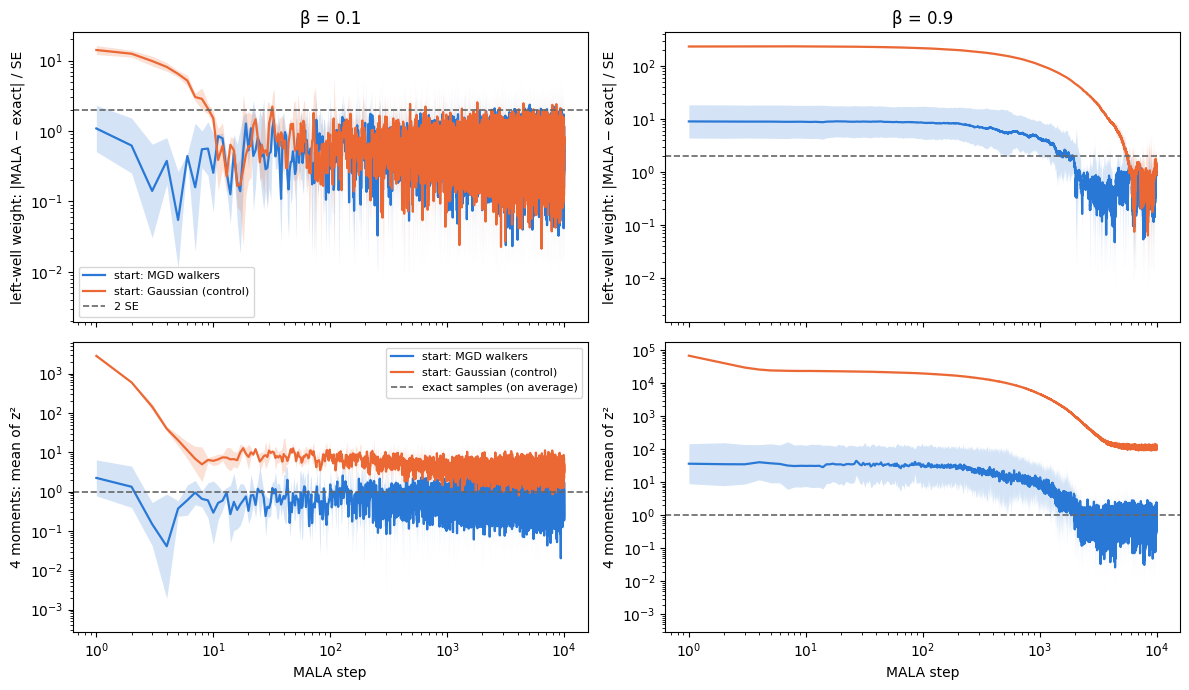

In [5]:
COLOR = {'mgd': CAT[0], 'gauss': CAT[1]}
LABEL = {'mgd': 'start: MGD walkers', 'gauss': 'start: Gaussian (control)'}

def convergence(s):
    """|z| of the left-well weight and mean z² over the 4 moments, per MALA step (exact p_reg as reference)."""
    N, ex = s['n_walkers'], s['exact']
    p = ex['p_below']
    zp = ((s['p_below'].double() - p).abs() / np.sqrt(p * (1 - p) / N)).numpy()
    z2 = torch.stack([((s['moments'][:, a].double() - ex['E'][a]) / np.sqrt(ex['cov'][a, a].item() / N)) ** 2
                      for a in range(4)]).mean(0).numpy()
    return np.maximum(zp, 1e-2), z2

fig, axes = plt.subplots(2, 2, figsize=(12, 7), sharex=True)
for col, b in enumerate(BETAS):
    for start in ('mgd', 'gauss'):
        c = [convergence(summary[b, k, start, 'A']) for k in RUNS]
        steps = np.arange(1, summary[b, 0, start, 'A']['steps'] + 1)
        gband(axes[0, col], steps, [ci[0][1:] for ci in c], COLOR[start], LABEL[start])
        gband(axes[1, col], steps, [ci[1][1:] for ci in c], COLOR[start], LABEL[start])
    axes[0, col].axhline(2, color='0.4', ls='--', lw=1.2, label='2 SE')
    axes[1, col].axhline(1, color='0.4', ls='--', lw=1.2, label='exact samples (on average)')
    axes[0, col].set(xscale='log', yscale='log', ylabel='left-well weight: |MALA − exact| / SE', title=f'β = {b}')
    axes[1, col].set(xscale='log', yscale='log', ylabel='4 moments: mean of z²', xlabel='MALA step')
axes[0, 0].legend(fontsize=8)
axes[1, 0].legend(fontsize=8)
fig.tight_layout()

**Conclusion.**
- From the MGD walkers MALA reaches p_reg: within a few steps at β = 0.1, after about 2000 steps at β = 0.9
  (the walkers start with the data's left-well weight, not p_reg's). A longer run is needed to see it stay there.
- The Gaussian control is not converged after 5000 steps: at β = 0.1 its fourth moment is still 2–3 SE off; at
  β = 0.9 everything is far off. A control from far away would need many more steps on turbulence.

## 4. Moment matching: MGD walkers versus samples of the regularised model

- Per moment: |sample average − data average| / data SE, for the MGD walkers and for the MALA samples of
  p_reg(λ_A) (MGD start, last step).
- The MALA values can be trusted: section 3 shows MALA reaches p_reg.
- This is the check available in high dimension, where only samples exist.

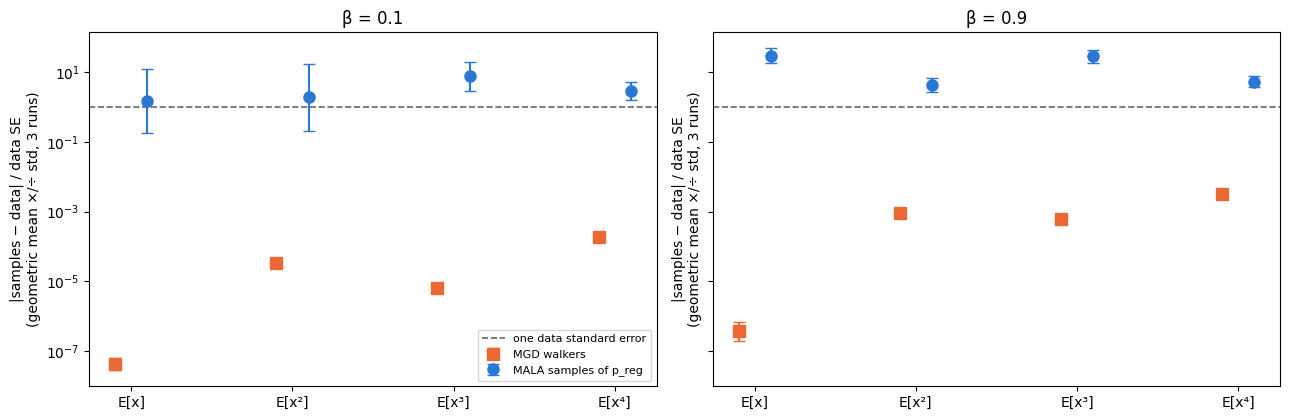

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.3), sharey=True)
for ax, b in zip(axes, BETAS):
    m, se = [np.array([data[b][k][key].numpy() for k in RUNS]) for key in ('m', 'se')]
    walk = np.array([(mgd[b, k]['x_final'].double()[:, None] ** A).mean(0).numpy() for k in RUNS])
    mala = np.array([summary[b, k, 'mgd', 'A']['moments'][-1].double().numpy() for k in RUNS])
    for lab, E, c, mk, off in (('MGD walkers', walk, CAT[1], 's', -0.1), ('MALA samples of p_reg', mala, CAT[0], 'o', 0.1)):
        g, s = gmean(np.abs(E - m) / se)
        ax.errorbar(np.arange(4) + off, g, yerr=[g - g / s, g * s - g], fmt=mk, color=c, ms=8, capsize=4, label=lab)
    ax.axhline(1, color='0.4', ls='--', lw=1.2, label='one data standard error')
    ax.set(xticks=range(4), xticklabels=MOMENTS, yscale='log', title=f'β = {b}',
           ylabel='|samples − data| / data SE\n(geometric mean ×/÷ std, 3 runs)')
axes[0].legend(fontsize=8)
fig.tight_layout()

**Conclusion.**
- MGD walkers: matched, by construction.
- Samples of p_reg: even moments a few SE off, odd moments E[x], E[x³] up to tens of SE (they carry the asymmetry
  between the wells, which the regularisation smooths).
- The regularised model does not reproduce the data moments: it needs correcting.

## 5. Correcting the mismatch

### 5a. Choosing λ by moment matching

- λ_D = the λ with the smallest moment mismatch D. Uses only the data (in high dimension: one MALA run per λ).
- λ_oracle = the λ closest to the truth (needs the truth; table only).
- Figure: D(λ) and KL(λ), average over runs; orange line = λ_A; dashed = data noise. Table: λ per run.

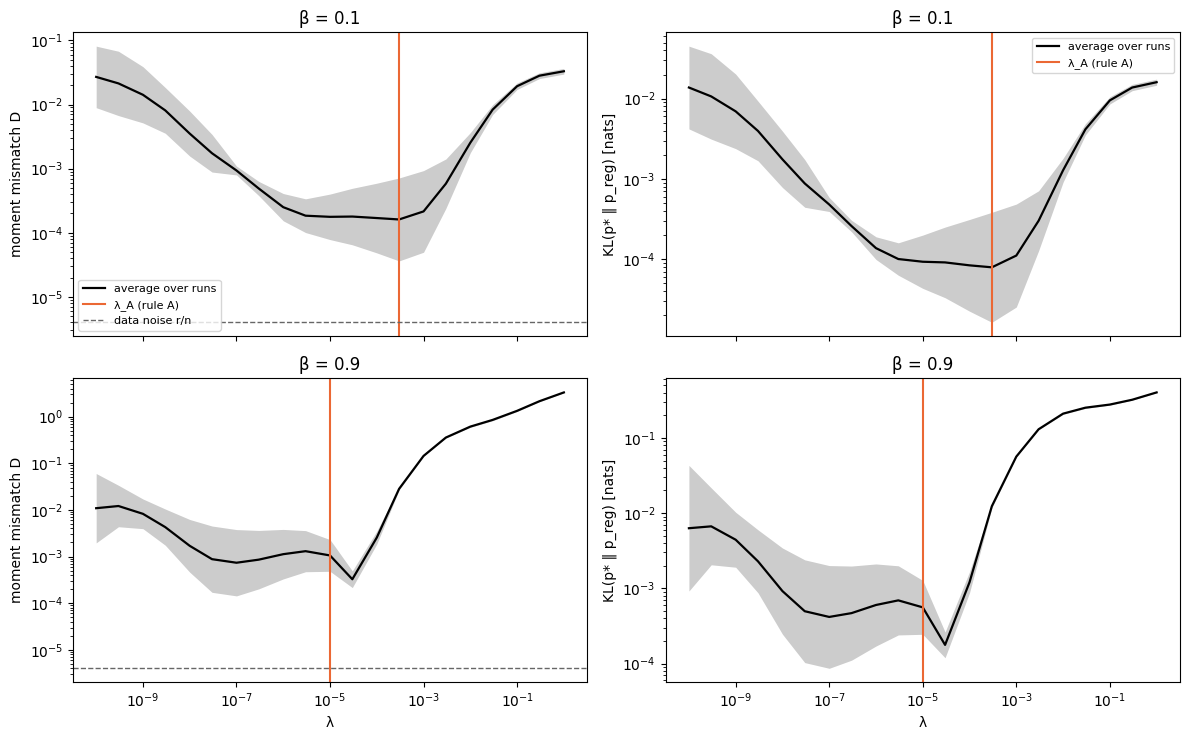

In [7]:
rows, scan = [], {}
for b in BETAS:
    for k in RUNS:
        Th = sel[b]['theta_final_reg'][k].double()
        D = np.array([mismatch(moments(th)[0], b, k) for th in Th])
        KL = kl_exact(theta_star(b), Th).numpy()
        scan[b, k] = (D, KL)
        iA, iD, iO = LAMS.index(sel[b]['lam_selected']), int(np.argmin(D)), int(np.argmin(KL))
        rows.append({'β': f'{b:g}', 'run': k, 'λ_A': LAMS[iA], 'λ_D': LAMS[iD], 'λ_oracle': LAMS[iO],
                     'D(λ_A)': D[iA], 'D(λ_D)': D[iD], 'KL(λ_A)': KL[iA], 'KL(λ_D)': KL[iD]})
lam_table = pd.DataFrame(rows).set_index(['β', 'run'])

lam_pos = np.array(LAMS[1:])                                   # lam = 0 cannot be shown on a log axis
fig, axes = plt.subplots(2, 2, figsize=(12, 7.5), sharex=True)
for row, b in enumerate(BETAS):
    for j, (ax, ylab) in enumerate(zip(axes[row], ('moment mismatch D', 'KL(p* ‖ p_reg) [nats]'))):
        gband(ax, lam_pos, [scan[b, k][j][1:] for k in RUNS], 'k', 'average over runs')
        ax.axvline(sel[b]['lam_selected'], color=CAT[1], lw=1.5, label='λ_A (rule A)')
        ax.set(xscale='log', yscale='log', ylabel=ylab, title=f'β = {b}')
    axes[row, 0].axhline(R / N_DATA, color='0.4', ls='--', lw=1, label='data noise r/n')
for ax in axes[1]:
    ax.set_xlabel('λ')
axes[0, 0].legend(fontsize=8)
axes[0, 1].legend(fontsize=8)
fig.tight_layout()
lam_table[['λ_A', 'λ_D', 'λ_oracle']].style.format('{:.0e}')

- λ_A and λ_D side by side: distance to the truth (top), moment mismatch (bottom).

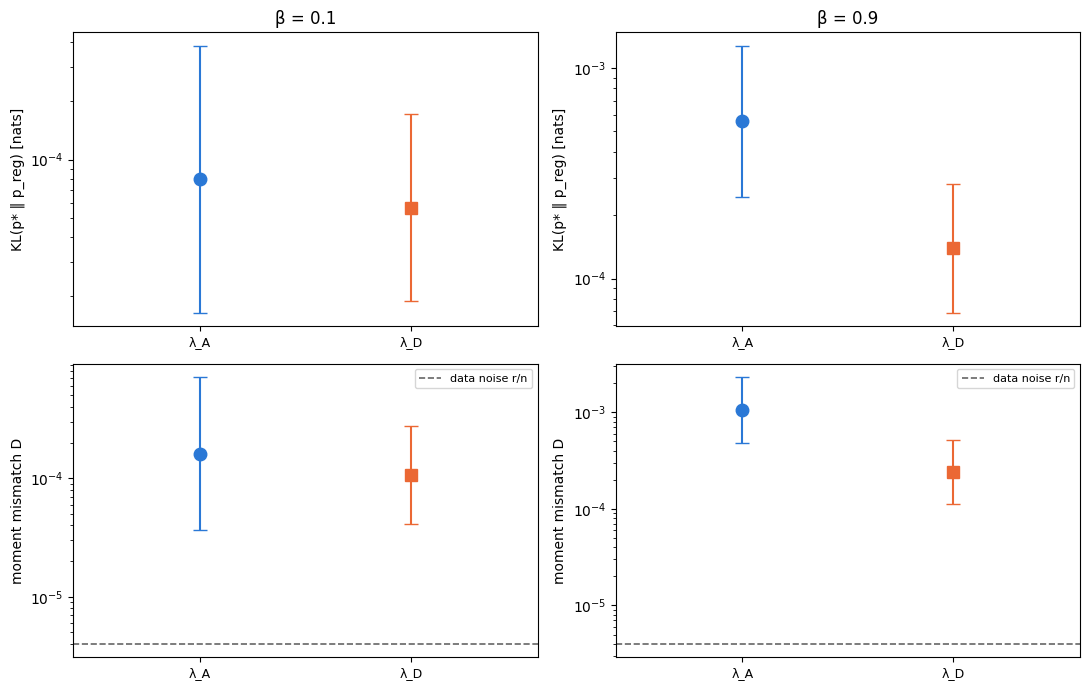

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for col, b in enumerate(BETAS):
    t = lam_table.loc[f'{b:g}']
    gpoints(axes[0, col], {f'λ_{c}': t[f'KL(λ_{c})'].values for c in ('A', 'D')}, 'KL(p* ‖ p_reg) [nats]',
            title=f'β = {b}')
    gpoints(axes[1, col], {f'λ_{c}': t[f'D(λ_{c})'].values for c in ('A', 'D')}, 'moment mismatch D',
            refs=[(R / N_DATA, 'data noise r/n')])
fig.tight_layout()

- MALA at λ_D vs λ_A: D measured on the MALA samples and exact, average over runs.

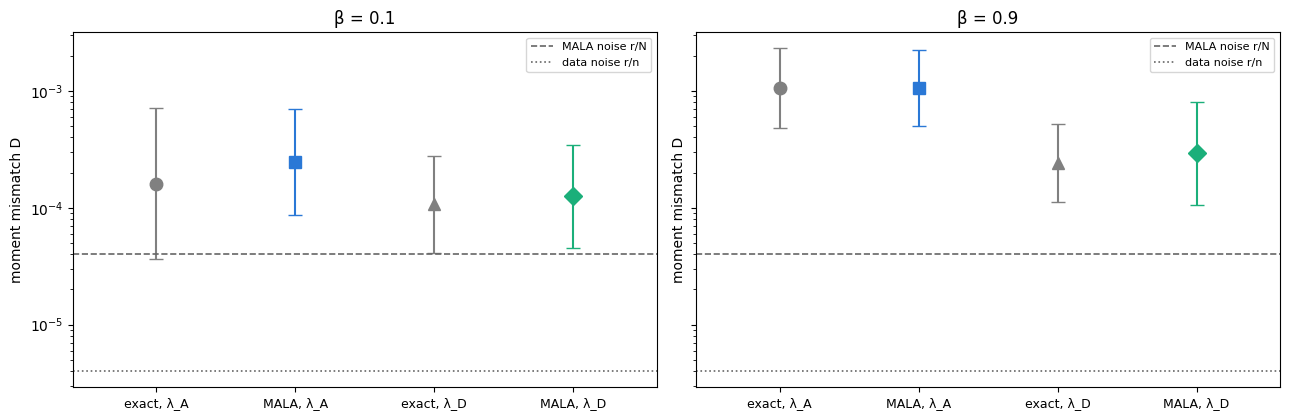

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.3), sharey=True)
for ax, b in zip(axes, BETAS):
    series = {}
    for rule in ('A', 'D'):
        series[f'exact, λ_{rule}'] = [mismatch(summary[b, k, 'mgd', rule]['exact']['E'], b, k) for k in RUNS]
        series[f'MALA, λ_{rule}'] = [mismatch(summary[b, k, 'mgd', rule]['moments'][-1], b, k) for k in RUNS]
    gpoints(ax, series, 'moment mismatch D', title=f'β = {b}', colors=['0.5', CAT[0], '0.5', CAT[2]],
            refs=[(R / summary[b, 0, 'mgd', 'A']['n_walkers'], 'MALA noise r/N'), (R / N_DATA, 'data noise r/n')])
fig.tight_layout()

**Conclusion.**
- λ_D equals the oracle λ in 5 of 6 runs (table); at β = 0.9 it lowers KL and D about 4×; MALA sees the same drop.
- But D(λ_D) stays 11–130× the data noise: no λ makes p_reg reproduce the data. Adjusting λ is not enough.

### 5b. Newton refit with moments from MALA

The maximum-entropy model is the p_θ whose moments equal m (= maximum likelihood, unique). Newton finds it:

```
start:  θ = Θ_reg(λ_A)
repeat (5 times):
  1. model:     p_θ(x) = exp(θ·φ(x)) / Z
  2. MALA:      10⁶ chains on p_θ (3000 steps to adapt, 1000 to average)  →  E_θ[φ], Cov_θ(φ)
  3. mismatch:  g = E_θ[φ] − m              (m = data moments)
  4. update:    θ ← θ − Cov_θ(φ)⁻¹ · g
```

- Chains kept from one iteration to the next (started once from the MGD walkers).
- Figure: KL and exact D of each iterate, average over runs.

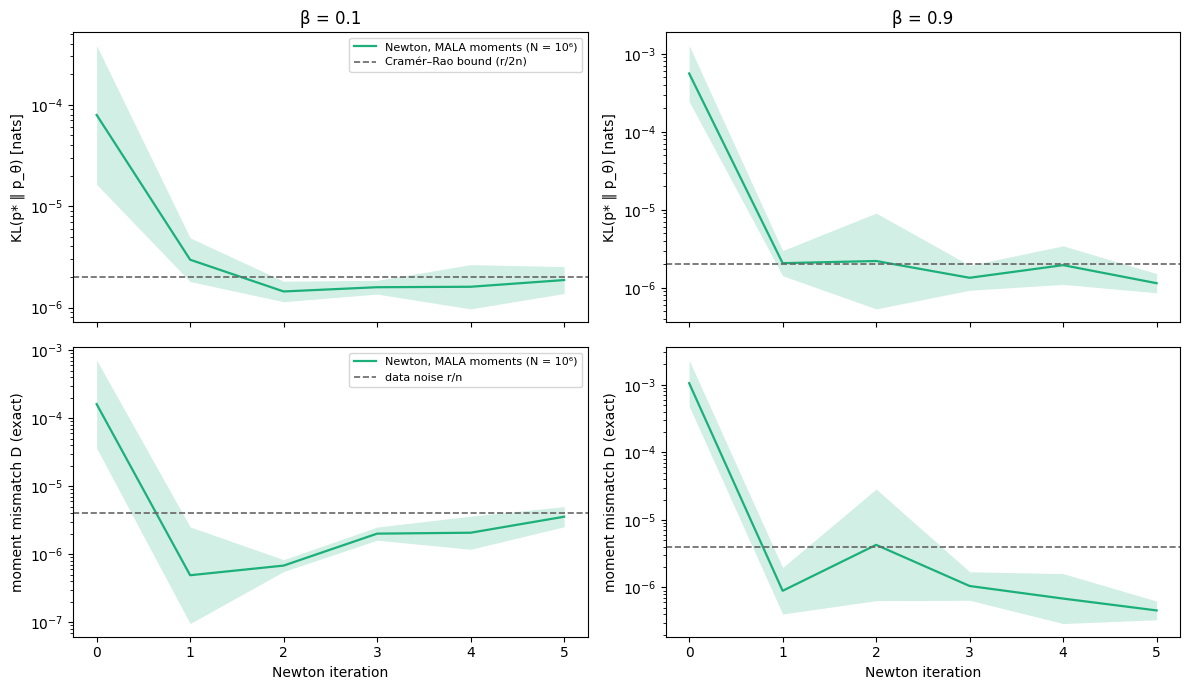

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7), sharex=True)
for col, b in enumerate(BETAS):
    rr = newton_mala(b)
    it = [i['iter'] for i in rr[0]['iterates']]
    for ax, key in zip(axes[:, col], ('KL', 'D_exact')):
        gband(ax, it, [[max(i[key], 1e-9) for i in r['iterates']] for r in rr], CAT[2], f'Newton, MALA moments (N = 10⁶)')
    axes[0, col].axhline(CR, color='0.4', ls='--', lw=1.2, label='Cramér–Rao bound (r/2n)')
    axes[1, col].axhline(R / N_DATA, color='0.4', ls='--', lw=1.2, label='data noise r/n')
    axes[0, col].set(yscale='log', ylabel='KL(p* ‖ p_θ) [nats]', title=f'β = {b}')
    axes[1, col].set(yscale='log', ylabel='moment mismatch D (exact)', xlabel='Newton iteration')
axes[0, 0].legend(fontsize=8)
axes[1, 0].legend(fontsize=8)
fig.tight_layout()

- Final KL relative to the Cramér–Rao bound (MALA: average over iterations 3–5, where the iterates only
  fluctuate), next to Newton with exact moments (integrals on the grid, possible only in 1-D) as reference.

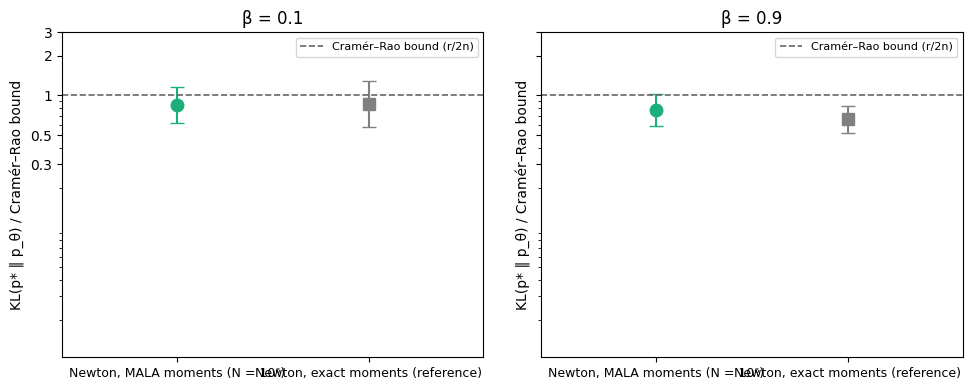

In [11]:
paths = {(b, k): newton(theta_reg(b, k, sel[b]['lam_selected']), data[b][k]['m'], max_iter=10)
         for b in BETAS for k in RUNS}
kl_newton_mala = {b: [np.mean([i['KL'] for i in r['iterates'][3:]]) for r in newton_mala(b)] for b in BETAS}
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
for ax, b in zip(axes, BETAS):
    ser = {'Newton, MALA moments (N = 10⁶)': np.array(kl_newton_mala[b]) / CR,
           'Newton, exact moments (reference)': [float(kl_exact(theta_star(b), paths[b, k][-1])[0]) / CR for k in RUNS]}
    gpoints(ax, ser, 'KL(p* ‖ p_θ) / Cramér–Rao bound', refs=[(1, 'Cramér–Rao bound (r/2n)')], title=f'β = {b}',
            colors=[CAT[2], '0.5'])
    ax.set_yticks([0.3, 0.5, 1, 2, 3], ['0.3', '0.5', '1', '2', '3'])
fig.tight_layout()

**Conclusion.**
- One Newton step brings the model to the Cramér–Rao bound; afterwards the iterates only fluctuate around it.
- The moment mismatch drops below the data noise: the refitted model reproduces the data moments.
- Same result as with exact moments: MALA's sampling noise does not matter with 10⁶ chains.
- With 10 times fewer chains (10⁵, not shown) the refit stalls 1–8× above the bound: each step needs about as many
  MALA samples as there are data samples.
- Here r = 4; with hundreds of statistics (turbulence) Cov_θ(φ) from samples is itself noisy, not tested here.

### 5c. Summary: distance to the truth along the pipeline

- KL(p\* ‖ p) for MGD's raw coefficients, the regularised model at λ_A and λ_D, and after the Newton refit with
  MALA moments; average over the 3 runs.

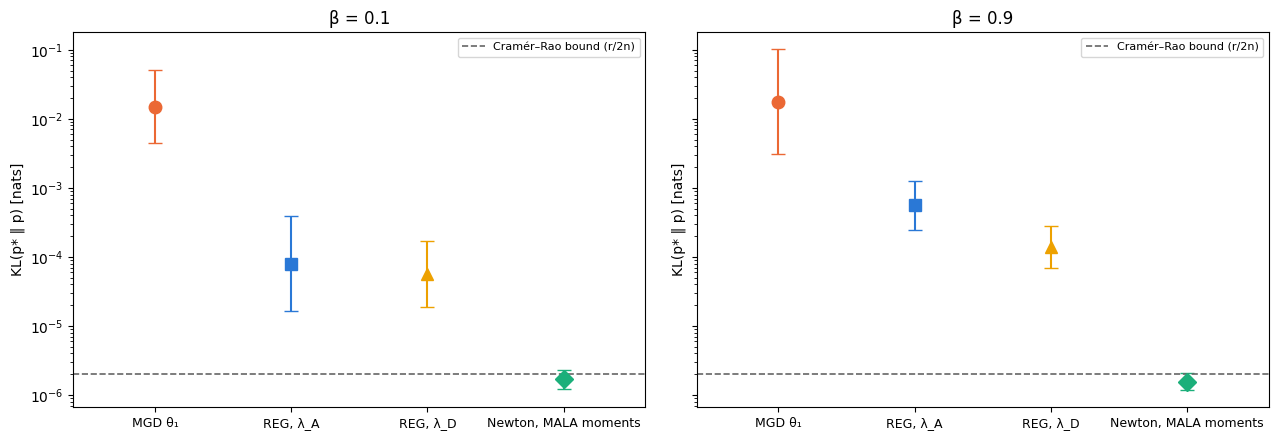

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for ax, b in zip(axes, BETAS):
    t = lam_table.loc[f'{b:g}']
    ser = {'MGD θ₁': [float(kl_exact(theta_star(b), mgd[b, k]['theta_final_mgd'].double())[0]) for k in RUNS],
           'REG, λ_A': t['KL(λ_A)'].values, 'REG, λ_D': t['KL(λ_D)'].values,
           'Newton, MALA moments': kl_newton_mala[b]}
    gpoints(ax, ser, 'KL(p* ‖ p) [nats]', refs=[(CR, 'Cramér–Rao bound (r/2n)')], title=f'β = {b}',
            colors=[CAT[1], CAT[0], CAT[3], CAT[2]])
fig.tight_layout()

**Conclusion.**
- Each stage brings the model closer to the truth; the Newton refit is the step that reaches the Cramér–Rao bound.

## 6. Appendix: checks of the exact computation

- **Grid:** exact values use 8001 points on [−10, 10]; compared at β = 0.9 with 64001 points on [−20, 20].
- **Valid densities:** exp(θ·φ) is a density only if θ₄ < 0; checked for θ₁ and for Θ_reg at every λ, 100 runs per β.

In [13]:
def exact_on(theta, lo, hi, n):
    x = np.linspace(lo, hi, n)
    lv = np.stack([x, x**2 / 2, x**3 / 3, x**4 / 4], 1) @ np.asarray(theta)
    w = np.exp(lv - lv.max())
    log_z = np.log(w.sum() * (x[1] - x[0])) + lv.max()
    w /= w.sum()
    return np.array([log_z, *(w @ x[:, None] ** np.arange(1, 5)), w[x < X_B].sum()])

b = max(BETAS)
for name, th in (('θ*', theta_star(b)), ('Θ_reg(λ_A), run 0', theta_reg(b, 0, sel[b]['lam_selected']))):
    a, c = exact_on(th, -10, 10, 8001), exact_on(th, -20, 20, 64001)
    print(f'β = {b}, {name}: largest relative difference between the two grids = {np.max(np.abs(a - c) / np.abs(c)):.1e}')
for b in BETAS:
    th_reg = sel[b]['theta_final_reg'][..., 3]
    ok_reg, ok_1 = int((th_reg < 0).sum()), sum(int(mgd[b, k]['theta_final_mgd'][3] < 0) for k in RUNS)
    print(f'β = {b}: valid densities (θ₄ < 0): Θ_reg {ok_reg} of {th_reg.numel()} (runs × λ), θ₁ {ok_1} of {len(RUNS)}')

β = 0.9, θ*: largest relative difference between the two grids = 1.1e-05
β = 0.9, Θ_reg(λ_A), run 0: largest relative difference between the two grids = 1.1e-05
β = 0.1: valid densities (θ₄ < 0): Θ_reg 2200 of 2200 (runs × λ), θ₁ 3 of 3
β = 0.9: valid densities (θ₄ < 0): Θ_reg 2200 of 2200 (runs × λ), θ₁ 3 of 3
